Recipe Lab — GPT-2 Full Fine-tuning vs. LoRA
Name: Anant Arya
Roll number: A24ARIU0014

All eight core exercises are implemented. The optional Llama extension is completed but disabled by default. Run in a fresh Colab or Kaggle session with a GPU and internet. The full experiment uses two training epochs and all eligible training recipes; set TRAIN_LIMIT = 200 for a limited-data execution check and label that run accordingly.

The dataset, model, and metrics are downloaded during execution. Actual losses, scores, training times, memory, and recipe outputs are not precomputed. Both runs use the supplied prompt format, dish-group split, data, batch size, epochs, cosine schedule, and greedy decoding. Their learning rates differ as specified in the lab. Models are moved to CPU between stages to avoid keeping three copies on the GPU during training.

In [1]:
# Run this setup cell first. Colab and Kaggle normally already include torch.
import importlib.util, subprocess, sys
for package,module in [("transformers","transformers"),("peft","peft"),("accelerate","accelerate"),
                       ("pandas","pandas"),("matplotlib","matplotlib"),
                       ("sacrebleu","sacrebleu"),("rouge_score","rouge_score")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",package])
# If PEFT reports an incompatible torchao, run %pip uninstall -y torchao
# in a separate cell, restart the runtime, and run all cells again.


In [2]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # Kaggle "T4 x2": train on one GPU only

import gc
import json
import shutil
import hashlib
import math
import random
import re
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import transformers

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
GB = 1e9
CKPT = "openai-community/gpt2"
MAX_LEN = 768            # longest training example in tokens; longer ones are dropped, not truncated
MAX_NEW = 400            # longest generated method, in tokens
N_EVAL = 40              # validation recipes for BLEU/ROUGE and reading
EPOCHS = 2
BATCH = 8
TRAIN_LIMIT = None       # e.g. 200 for a quick smoke run; None for the real run
OUT = Path("/kaggle/working/recipe_lab") if Path("/kaggle/working").is_dir() else Path("recipe_lab_outputs")
DATA_DIR, ADAPTER_DIR = OUT / "data", OUT / "adapter"
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda" if HAS_GPU else "cpu"

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (Exercises 1-3 only)")
print("Output folder:", OUT.resolve())


torch 2.11.0+cu130 | transformers 5.20.2
GPU: Tesla T4
Output folder: /content/recipe_lab_outputs


In [3]:
DATA_URL = ("https://data.mendeley.com/public-files/datasets/xsphgmmh7b/files/"
            "6fb5ae32-a815-4b8f-9d68-8d512227eac8/file_downloaded")
DATA_SHA256 = "273f8d45f41aca9af0396dda07af137c68c7387a1506992904144b944c4346be"
csv_path = DATA_DIR / "IndianFoodDatasetCSV.csv"
DATA_DIR.mkdir(parents=True, exist_ok=True)
# Use an uploaded CSV if one is already present in Colab/Kaggle.
if not csv_path.exists():
    candidates = list(Path("/content").glob("*.csv")) if Path("/content").exists() else []
    if Path("/kaggle/input").exists():
        candidates += list(Path("/kaggle/input").rglob("IndianFoodDatasetCSV.csv"))
    found = next((p for p in candidates if p.name == "IndianFoodDatasetCSV.csv"), None)
    if found is not None: shutil.copyfile(found, csv_path)
if not csv_path.exists():
    print("Downloading dataset to", csv_path)
    try:
        request = urllib.request.Request(DATA_URL, headers={"User-Agent": "recipe-lab"})
        with urllib.request.urlopen(request, timeout=60) as response:
            csv_path.write_bytes(response.read())
    except Exception as error:
        print("Automatic download failed:", error)
        print("Download IndianFoodDatasetCSV.csv from https://doi.org/10.17632/xsphgmmh7b.1")
        if Path("/content").is_dir():
            from google.colab import files
            uploaded = files.upload()
            chosen = next((name for name in uploaded if name.lower().endswith(".csv")), None)
            if chosen is None: raise ValueError("Please upload the recipe CSV")
            csv_path.write_bytes(uploaded[chosen])
            del uploaded
        else:
            raise RuntimeError(f"Place the dataset CSV at {csv_path.resolve()} and rerun this cell") from error
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == DATA_SHA256, "unexpected file: delete it and download again"

raw = pd.read_csv(csv_path, encoding="utf-8-sig")
raw = raw.dropna(subset=["RecipeName", "Ingredients", "Instructions", "Cuisine"])
raw = raw.apply(lambda col: col if pd.api.types.is_numeric_dtype(col) else col.str.replace("\ufeff", "").str.strip())
print(raw.shape)
print(raw.columns.tolist())
raw.iloc[0][["RecipeName", "Cuisine", "Course", "Diet", "Ingredients", "Instructions"]].to_dict()

(6865, 15)
['Srno', 'RecipeName', 'TranslatedRecipeName', 'Ingredients', 'TranslatedIngredients', 'PrepTimeInMins', 'CookTimeInMins', 'TotalTimeInMins', 'Servings', 'Cuisine', 'Course', 'Diet', 'Instructions', 'TranslatedInstructions', 'URL']


{'RecipeName': 'Masala Karela Recipe',
 'Cuisine': 'Indian',
 'Course': 'Side Dish',
 'Diet': 'Diabetic Friendly',
 'Ingredients': '6 Karela (Bitter Gourd/ Pavakkai) - deseeded,Salt - to taste,1 Onion - thinly sliced,3 tablespoon Gram flour (besan),2 teaspoons Turmeric powder (Haldi),1 tablespoon Red Chilli powder,2 teaspoons Cumin seeds (Jeera),1 tablespoon Coriander Powder (Dhania),1 tablespoon Amchur (Dry Mango Powder),Sunflower Oil - as required',
 'Instructions': 'To begin making the\xa0Masala Karela Recipe,de-seed the karela and slice. Do not remove the skin as the skin has all the nutrients.\xa0Add the karela to the pressure cooker with 3 tablespoon of water, salt and turmeric powder and pressure cook for three whistles. Release the pressure immediately and open the lids. Keep aside.Heat oil in a heavy bottomed pan or a kadhai. Add cumin seeds and let it sizzle.Once the cumin seeds have sizzled, add onions and saute them till it turns golden brown in color.Add the karela,\xa0red

Filter English originals and Indian cuisines

In [4]:
DEVANAGARI = r"[\u0900-\u097F]"
NOT_INDIAN = {"Afghan", "African", "American", "Arab", "Asian", "British", "Burmese", "Cantonese", "Caribbean",
              "Chinese", "Continental", "European", "French", "Fusion", "Greek", "Hunan", "Indonesian",
              "Italian Recipes", "Japanese", "Jewish", "Korean", "Malaysian", "Mediterranean", "Mexican",
              "Middle Eastern", "Nepalese", "Pakistani", "Shandong", "Sichuan", "Sri Lankan", "Thai",
              "Vietnamese", "World Breakfast",
              "Appetizer", "Brunch", "Dessert", "Dinner", "Lunch", "Side Dish", "Snack"}   # courses, not cuisines


def clean_text(t):
    t = re.sub(r"\.(?=[A-Z])", ". ", t)        # "aside.Heat" -> "aside. Heat"
    t = re.sub(r",(?=[A-Za-z])", ", ", t)       # "Recipe,de-seed" -> "Recipe, de-seed"
    return " ".join(t.split())


def clean_name(name):
    return " ".join(re.sub(r"\brecipe\b", "", name, flags=re.IGNORECASE).split()).strip(" -")


english = ~(raw["RecipeName"].str.contains(DEVANAGARI) | raw["Ingredients"].fillna("").str.contains(DEVANAGARI)
            | raw["Instructions"].str.contains(DEVANAGARI))
kept = raw[english & raw["Ingredients"].notna() & ~raw["Cuisine"].isin(NOT_INDIAN)]
recipes = [{"raw_name": r.RecipeName, "name": clean_name(r.RecipeName), "cuisine": r.Cuisine,
            "course": r.Course, "diet": r.Diet,
            "ingredients": [i.strip() for i in r.Ingredients.split(",") if i.strip()],
            "method": clean_text(r.Instructions)} for r in kept.itertuples()]
print(f"{len(raw):,} rows -> {english.sum():,} English originals -> {len(recipes):,} Indian recipes")
print(kept["Cuisine"].value_counts().head(8).to_string())

6,865 rows -> 5,653 English originals -> 3,708 Indian recipes
Cuisine
Indian                   870
North Indian Recipes     688
South Indian Recipes     503
Maharashtrian Recipes    144
Bengali Recipes          140
Karnataka                132
Kerala Recipes           126
Tamil Nadu               124


Exercise 1 — Dish grouping

In [5]:
def dish_key(raw_name):
    name = re.split(r" - |\(", raw_name.lower(), maxsplit=1)[0]
    name = re.sub(r"\brecipes?\b", " ", name)
    name = re.sub(r"[^a-z ]", " ", name)
    return " ".join(name.split())

In [6]:
assert dish_key("Aamras Recipe - Ripe Mango Ras") == dish_key("Aamras Recipe") == "aamras"
assert dish_key("Achari Paneer Masala Recipe") == "achari paneer masala"
assert dish_key("Bengali Doi Maach Recipe (Fish In Yogurt Curry)") == "bengali doi maach"
for r in recipes:
    r["key"] = dish_key(r["raw_name"])

# Group split: shuffle the distinct keys, then 80% / 10% / 10% of the keys -> train / validation / test
keys = sorted({r["key"] for r in recipes})
random.Random(SEED).shuffle(keys)
n_val = n_test = len(keys) // 10
split_of = {k: "val" for k in keys[:n_val]} | {k: "test" for k in keys[n_val:n_val + n_test]} \
         | {k: "train" for k in keys[n_val + n_test:]}
splits = {s: [r for r in recipes if split_of[r["key"]] == s] for s in ("train", "val", "test")}
assert not ({r["key"] for r in splits["train"]} & {r["key"] for r in splits["val"] + splits["test"]})
print({s: len(rs) for s, rs in splits.items()}, f"| {len(keys):,} distinct dishes")

# What a random *row* split would have done
shuffled = random.Random(SEED).sample(recipes, len(recipes))
row_val, row_train = shuffled[:len(recipes) // 10], shuffled[len(recipes) // 10:]
train_keys = {r["key"] for r in row_train}
twins = [r for r in row_val if r["key"] in train_keys]
print(f"random row split: {len(twins)} of {len(row_val)} validation recipes have a same-dish twin in training")
for r in twins[:3]:
    print("  ", r["raw_name"], "<->", next(t["raw_name"] for t in row_train if t["key"] == r["key"]))
assert not ({r["key"] for r in splits["val"]} & {r["key"] for r in splits["test"]})
print("Exercise 1 checks passed.")
print(f"Answer 1(a): a row split leaks {len(twins)} of {len(row_val)} validation recipes.")

{'train': 2970, 'val': 369, 'test': 369} | 3,694 distinct dishes
random row split: 6 of 370 validation recipes have a same-dish twin in training
   Badam Halwa Recipe - Delicious Almond Halwa With Khoya <-> Badam Halwa Recipe
   Jal Jeera Recipe - Sweet And Sour Cumin Water Recipe <-> Jal Jeera Recipe - Indian Spiced Lemonade
   Muttaikose Poriyal Recipe -  Purple Cabbage Poriyal | Red Cabbage Sabzi <-> Muttaikose Poriyal Recipe - Cabbage Stir fry With Coconut
Exercise 1 checks passed.
Answer 1(a): a row split leaks 6 of 370 validation recipes.


Prompt format and tokenizer


In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CKPT)     # a few MB; the model is downloaded in Exercise 4
tokenizer.pad_token = tokenizer.eos_token           # GPT-2 has no pad token; padding is masked anyway


def format_prompt(r):
    ingredients = "\n".join(f"- {i}" for i in r["ingredients"])
    return (f"Dish: {r['name']}\nCuisine: {r['cuisine']} | Course: {r['course']} | Diet: {r['diet']}\n"
            f"Ingredients:\n{ingredients}\nMethod:\n")


def prompt_ids(r, tok, add_bos):
    """Token IDs of the prompt. GPT-2 uses no beginning-of-text token; Llama does (see the extension)."""
    ids = tok(format_prompt(r), add_special_tokens=False)["input_ids"]
    return ([tok.bos_token_id] if add_bos else []) + ids


r0 = splits["train"][0]
print(format_prompt(r0) + r0["method"][:300] + " …")
print("\nend-of-text token:", repr(tokenizer.eos_token), tokenizer.eos_token_id)
for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
    print(f"{word:>8} -> {tokenizer.tokenize(' ' + word)}")

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Dish: Ragi Semiya Upma - Ragi Millet Vermicelli Breakfast
Cuisine: South Indian Recipes | Course: South Indian Breakfast | Diet: High Protein Vegetarian
Ingredients:
- 1-1/2 cups Rice Vermicelli Noodles (Thin)
- 1 Onion - sliced
- 1/2 cup Carrots (Gajjar) - chopped
- 1/3 cup Green peas (Matar)
- 2 Green Chillies
- 1/4 teaspoon Asafoetida (hing)
- 1 teaspoon Mustard seeds
- 1 teaspoon White Urad Dal (Split)
- 1 teaspoon Ghee
- 1 sprig Curry leaves
- Salt - to taste
- 1 teaspoon Lemon juice
Method:
To begin making the Ragi Vermicelli Recipe, first steam the ragi vermicelli in a rice cooker or a steamer for about 5-6 minutes or till it is cooked but firm. Keep aside this aside till later use. You can add a few drops of oil and mix it so that they don't stick to each other. Place a kadai on the  …

end-of-text token: '<|endoftext|>' 50256
  potato -> ['Ġpotato']
   cumin -> ['Ġc', 'umin']
  karela -> ['Ġk', 'are', 'la']
  amchur -> ['Ġam', 'ch', 'ur']
  kadhai -> ['Ġk', 'adh', 'ai']
   tad

Exercise 2 — Method-only labels and EOS

In [8]:
def build_example(r, tok, add_bos):
    p = prompt_ids(r, tok, add_bos)
    answer = tok(r["method"], add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    return {"input_ids": p + answer, "attention_mask": [1] * (len(p) + len(answer)),
            "labels": [-100] * len(p) + answer}

In [9]:
ex = build_example(r0, tokenizer, add_bos=False)
n_prompt = len(prompt_ids(r0, tokenizer, add_bos=False))
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "method labels must equal the method tokens"
assert ex["input_ids"][-1] == tokenizer.eos_token_id, "the method must end with the end-of-text token"
assert tokenizer.decode(ex["input_ids"][:n_prompt], clean_up_tokenization_spaces=False) == format_prompt(r0)
print(f"{len(ex['input_ids'])} tokens, {len(ex['input_ids']) - n_prompt} of them scored")
print("scored text ends with:", repr(tokenizer.decode([t for t in ex["labels"] if t != -100])[-80:]))


def make_dataset(rows, tok, add_bos):
    data = [build_example(r, tok, add_bos) for r in rows]
    return [e for e in data if len(e["input_ids"]) <= MAX_LEN]


train_rows = splits["train"][:TRAIN_LIMIT]
train_data = make_dataset(train_rows, tokenizer, add_bos=False)
val_data = make_dataset(splits["val"], tokenizer, add_bos=False)
eval_rows = random.Random(SEED).sample(splits["val"], min(N_EVAL, len(splits["val"])))     # for generation and BLEU/ROUGE
lengths = sorted(len(build_example(r, tokenizer, False)["input_ids"]) for r in train_rows)
print(f"training examples: {len(train_data):,} kept of {len(train_rows):,} (> {MAX_LEN} tokens dropped)"
      f" | validation examples: {len(val_data)}")
print(f"tokens per example: median {lengths[len(lengths) // 2]}, 90th percentile {lengths[int(0.9 * len(lengths))]}, "
      f"max {lengths[-1]}")
print("Exercise 2 checks passed.")
assert train_data and val_data, "No usable examples: inspect dataset filters and MAX_LEN"
print("Answer 2(c): dropped",len(train_rows)-len(train_data),"of",len(train_rows),"training examples")

eval_rows = [r for r in eval_rows if len(prompt_ids(r, tokenizer, False)) + MAX_NEW <= 1024]
assert eval_rows, "No evaluation prompts fit GPT-2's context window"
print("Generation evaluation recipes:", len(eval_rows))


423 tokens, 261 of them scored
scored text ends with: 't Chutney and a hot cup of coffee or tea for a wholesome breakfast.<|endoftext|>'
training examples: 2,862 kept of 2,970 (> 768 tokens dropped) | validation examples: 359
tokens per example: median 430, 90th percentile 636, max 1337
Exercise 2 checks passed.
Answer 2(c): dropped 108 of 2970 training examples
Generation evaluation recipes: 40


Exercise 3 — BLEU and ROUGE

In [10]:
import sacrebleu
from rouge_score import rouge_scorer

ROUGE_KEYS = {"ROUGE-1": "rouge1", "ROUGE-2": "rouge2", "ROUGE-L": "rougeL"}
scorer = rouge_scorer.RougeScorer(list(ROUGE_KEYS.values()), use_stemmer=True)


def text_metrics(preds, refs):
    if len(preds) != len(refs) or not preds:
        raise ValueError("Provide equal, nonempty prediction/reference lists")
    result = {"BLEU": sacrebleu.corpus_bleu(preds, [refs]).score}
    scores = [scorer.score(reference, prediction) for prediction, reference in zip(preds, refs)]
    for label, key in ROUGE_KEYS.items():
        result[label] = 100 * sum(s[key].fmeasure for s in scores) / len(scores)
    return result

In [11]:
m = text_metrics(["heat oil in a pan"], ["heat the oil in a kadhai"])
print({k: round(v, 1) for k, v in m.items()})
assert abs(m["ROUGE-1"] - 72.7) < 0.1 and abs(m["ROUGE-2"] - 44.4) < 0.1 and abs(m["ROUGE-L"] - 72.7) < 0.1
assert abs(text_metrics(["add salt and stir well"], ["add salt and stir well"])["BLEU"] - 100) < 1e-6
print("Exercise 3 checks passed.")

{'BLEU': 35.0, 'ROUGE-1': 72.7, 'ROUGE-2': 44.4, 'ROUGE-L': 72.7}
Exercise 3 checks passed.


Ingredient mention coverage

In [12]:
UNITS = r"\b(cups?|tablespoons?|teaspoons?|tbsp|tsp|grams?|gms?|g|kg|ml|litres?|liters?|inch|pinch|sprigs?|cloves?|pieces?|nos?)\b"


def ingredient_words(ingredients):
    words = set()
    for item in ingredients:
        name = re.split(r" - |\(", item.lower())[0]
        name = re.sub(UNITS, " ", re.sub(r"[^a-z ]", " ", name))
        if name.split():
            words.add(name.split()[-1])
    return words


def ingredient_coverage(rows, methods):
    fractions = []
    for r, m in zip(rows, methods):
        words, text = ingredient_words(r["ingredients"]), set(re.findall(r"[a-z]+", m.lower()))
        fractions.append(len(words & text) / max(len(words), 1))
    return 100 * sum(fractions) / len(fractions)


print(sorted(ingredient_words(r0["ingredients"])))
print(f"reference methods mention {ingredient_coverage(eval_rows, [r['method'] for r in eval_rows]):.0f}% "
      "of their ingredient words (validation sample)")

['asafoetida', 'carrots', 'chillies', 'dal', 'ghee', 'juice', 'leaves', 'noodles', 'onion', 'peas', 'salt', 'seeds']
reference methods mention 77% of their ingredient words (validation sample)


Exercise 4 — Original GPT-2 baseline

In [13]:
from transformers import AutoModelForCausalLM


@torch.no_grad()
def generate_methods(model, tok, rows, add_bos, batch_size=8, max_new_tokens=MAX_NEW):
    model.eval()
    texts, stopped = [], []
    for i in range(0, len(rows), batch_size):
        prompts = [prompt_ids(r, tok, add_bos) for r in rows[i:i + batch_size]]
        width = max(len(p) for p in prompts)
        ids = torch.full((len(prompts), width), tok.pad_token_id)
        mask = torch.zeros((len(prompts), width), dtype=torch.long)
        for j, p in enumerate(prompts):
            ids[j, width - len(p):] = torch.tensor(p)
            mask[j, width - len(p):] = 1
        out = model.generate(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE), do_sample=False,
                             temperature=None, top_p=None, top_k=None, no_repeat_ngram_size=4,
                             max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id,
                             eos_token_id=tok.eos_token_id)
        for new in out[:, width:].tolist():
            stop = tok.eos_token_id in new
            new = new[:new.index(tok.eos_token_id)] if stop else new
            texts.append(tok.decode(new, skip_special_tokens=True).strip())
            stopped.append(stop)
    return texts, stopped


refs = [r["method"] for r in eval_rows]
results = {}                                        # model name -> metrics row


def evaluate(name, preds, stopped, rows=None):
    rows = eval_rows if rows is None else rows
    row = text_metrics(preds, [r["method"] for r in rows])
    row["ingredients %"] = ingredient_coverage(rows, preds)
    row["words"] = sum(len(p.split()) for p in preds) / len(preds)
    row["stopped %"] = 100 * sum(stopped) / len(stopped)
    results[name] = row
    return pd.DataFrame(results).T.round(1)


assert HAS_GPU, "Enable a GPU in Colab Runtime > Change runtime type, or Kaggle Settings > Accelerator; then restart and run all"
transformers.set_seed(SEED)
base_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
start = time.perf_counter()
base_preds, base_stopped = generate_methods(base_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {len(base_preds)} methods in {time.perf_counter() - start:.0f} s")
reference_row = {"ingredients %": ingredient_coverage(eval_rows, refs), "words": sum(len(t.split()) for t in refs) / len(refs)}
print("references:", {k: round(v, 1) for k, v in reference_row.items()})
evaluate("GPT-2 original", base_preds, base_stopped)
base_model.to("cpu")
gc.collect()
if HAS_GPU: torch.cuda.empty_cache()


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

generated 40 methods in 38 s
references: {'ingredients %': 76.9, 'words': 234.2}


In [14]:
for r, p in list(zip(eval_rows, base_preds))[:5]:
    print(f"=== {r['name']} ===\nMODEL:     {p[:600]}\nREFERENCE: {r['method'][:600]}\n")

=== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===
MODEL:     - In a large bowl, combine the milk, water, ginger, cardamom powder, cardamoms, and ghee. Add the milk and mix well. Add the yogurt and mix well again. Add the dry ginger powder and mix well, adding more milk if needed. Add the ginger and mix well and add more milk if necessary. Add the water and mix well to combine. Add the ghee and mix well until the mixture is smooth. Add the remaining milk and mix. Add the rest of the ingredients and mix well with a fork. Serve hot.
- Serve hot. Recipe Notes:
- The recipe is based on a recipe from the Indian Food Journal.
- The Indian Food Journal is a web
REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken.

Exercise 5 — Full fine-tuning

In [15]:
from transformers import Trainer, TrainingArguments

FULL_LR = 5e-5


def make_args(name, lr):
    return TrainingArguments(
        output_dir=str(OUT / name),
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH,
        num_train_epochs=EPOCHS, learning_rate=lr,
        lr_scheduler_type="cosine", warmup_steps=20,
        fp16=HAS_GPU, bf16=False,
        eval_strategy="epoch", logging_steps=20,
        save_strategy="no", report_to="none",
        remove_unused_columns=False, seed=SEED, data_seed=SEED,
        optim="adamw_torch", prediction_loss_only=True,
        label_names=["labels"],
    )

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,2.096572,1.986394
2,2.035223,1.939504


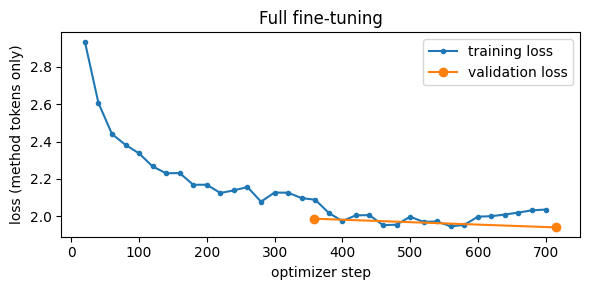

{'trainable': '124,439,808', 'minutes': 7.26, 'peak GB': 10.5} | final validation loss 1.94
Exercise 5 checks passed.


In [16]:
from accelerate.utils import extract_model_from_parallel


def collate(batch, pad_id=tokenizer.pad_token_id):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), pad_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train(model, args, train_data, eval_data, title, data_collator=collate):
    trainer = Trainer(model=model, args=args, train_dataset=train_data, eval_dataset=eval_data,
                      data_collator=data_collator)
    if HAS_GPU:
        torch.cuda.synchronize()
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    start = time.perf_counter()
    trainer.train()
    if HAS_GPU: torch.cuda.synchronize()
    extract_model_from_parallel(model, keep_fp32_wrapper=False)   # remove the fp16 autocast wrapper: evaluate in fp32
    stats = {"trainable": count_trainable(model), "minutes": (time.perf_counter() - start) / 60,
             "peak GB": torch.cuda.max_memory_allocated() / GB if HAS_GPU else float("nan")}
    log = trainer.state.log_history
    tr = [(h["step"], h["loss"]) for h in log if "loss" in h]
    ev = [(h["step"], h["eval_loss"]) for h in log if "eval_loss" in h]
    plt.figure(figsize=(6, 3))
    if tr:
        plt.plot(*zip(*tr), marker=".", label="training loss")
    plt.plot(*zip(*ev), marker="o", label="validation loss")
    plt.xlabel("optimizer step"); plt.ylabel("loss (method tokens only)"); plt.title(title)
    plt.legend(); plt.tight_layout(); plt.show()
    print({k: (f"{v:,}" if k == "trainable" else round(v, 2)) for k, v in stats.items()},
          "| final validation loss", round(ev[-1][1], 3))
    # Record the actual framework versions and both training curves.
    OUT.mkdir(parents=True, exist_ok=True)
    (OUT / (args.output_dir.split("/")[-1] + "_training.json")).write_text(
        json.dumps({"stats": stats, "log": log, "transformers": transformers.__version__}, indent=2))
    model.zero_grad(set_to_none=True)
    return stats, ev[-1][1]


transformers.set_seed(SEED)
full_model = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
full_stats, full_val_loss = train(full_model, make_args("full", FULL_LR), train_data, val_data, "Full fine-tuning")
assert full_stats["trainable"] == 124_439_808, "full fine-tuning trains every GPT-2 parameter"
print("Exercise 5 checks passed.")
full_model.to("cpu")
gc.collect()
if HAS_GPU: torch.cuda.empty_cache()


Exercise 6 — LoRA

In [22]:
from peft import LoraConfig, get_peft_model
%pip uninstall -y torchao
LORA_LR = 5e-4
transformers.set_seed(SEED)
lora_base = AutoModelForCausalLM.from_pretrained(CKPT).to(DEVICE)
predicted_lora_params = 12 * 8 * (768 + 2304)
lora_config = LoraConfig(
    r=8, lora_alpha=16, lora_dropout=0.05,
    target_modules=["c_attn"], task_type="CAUSAL_LM",
    fan_in_fan_out=True, bias="none",
)
lora_model = get_peft_model(lora_base, lora_config)

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

In [24]:
lora_model.print_trainable_parameters()
assert count_trainable(lora_model) == predicted_lora_params, "your prediction does not match peft's count"
assert predicted_lora_params == 294_912, "check the shapes of A and B"
print("Exercise 6 configuration checks passed.")

trainable params: 294,912 || all params: 124,734,720 || trainable%: 0.2364
Exercise 6 configuration checks passed.


Epoch,Training Loss,Validation Loss
1,2.512891,2.355196
2,2.498212,2.313834


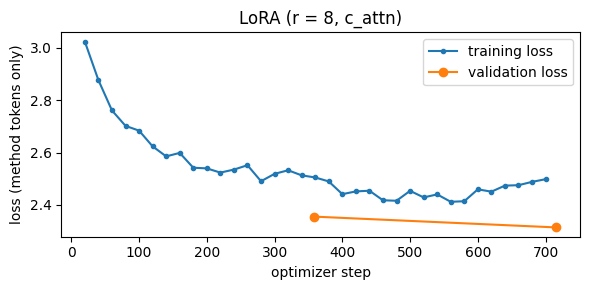

{'trainable': '294,912', 'minutes': 6.04, 'peak GB': 9.46} | final validation loss 2.314
Answer 5(a), full FT: {'trainable': 124439808, 'minutes': 7.2624028157, 'peak GB': 10.501779968} validation loss: 1.939503788948059
Answer 6, LoRA: {'trainable': 294912, 'minutes': 6.035900121683335, 'peak GB': 9.455049216} validation loss: 2.3138341903686523
LoRA trainable percentage: 0.2369916867759873
16-byte full-FT parameter-state estimate (GB): 1.991036928


In [25]:
lora_stats, lora_val_loss = train(lora_model, make_args("lora", LORA_LR), train_data, val_data, "LoRA (r = 8, c_attn)")
pd.DataFrame({"full fine-tuning": full_stats | {"val loss": full_val_loss},
              "LoRA": lora_stats | {"val loss": lora_val_loss}}).T
print("Answer 5(a), full FT:", full_stats, "validation loss:", full_val_loss)
print("Answer 6, LoRA:", lora_stats, "validation loss:", lora_val_loss)
print("LoRA trainable percentage:", 100 * predicted_lora_params / 124_439_808)
print("16-byte full-FT parameter-state estimate (GB):", 16 * 124_439_808 / GB)


Exercise 7 — Three-model comparison

In [26]:
start = time.perf_counter()
lora_model.to("cpu")
full_model.to(DEVICE)
full_preds, full_stopped = generate_methods(full_model, tokenizer, eval_rows, add_bos=False)
full_model.to("cpu")
if HAS_GPU: torch.cuda.empty_cache()
lora_model.to(DEVICE)
lora_preds, lora_stopped = generate_methods(lora_model, tokenizer, eval_rows, add_bos=False)
print(f"generated {2 * len(eval_rows)} methods in {time.perf_counter() - start:.0f} s")
evaluate("GPT-2 full FT", full_preds, full_stopped)
table = evaluate("GPT-2 LoRA", lora_preds, lora_stopped)
table
table.to_csv(OUT / "comparison.csv")
(OUT / "generated_methods.json").write_text(json.dumps(
    {"dishes": [r["name"] for r in eval_rows], "references": refs,
     "original": base_preds, "full": full_preds, "lora": lora_preds}, indent=2))
print(table.to_string())


generated 80 methods in 55 s
                BLEU  ROUGE-1  ROUGE-2  ROUGE-L  ingredients %  words  stopped %
GPT-2 original   3.7     30.8      6.9     17.4           56.3  219.0       65.0
GPT-2 full FT   10.4     46.4     17.7     29.4           76.5  167.4       97.5
GPT-2 LoRA       9.5     42.0     14.2     25.9           74.4  228.0       85.0


In [27]:
for i in range(min(3, len(eval_rows))):
    r = eval_rows[i]
    print(f"=================== {r['name']} ===================")
    print("INGREDIENTS:", "; ".join(r["ingredients"]))
    for name, preds in (("REFERENCE", refs), ("FULL FT", full_preds), ("LORA", lora_preds)):
        print(f"\n{name}: {preds[i][:700]}")
    print()

=================== Sweet Ragi Malt - Healthy Ragi Kanji/ Porridge ===================
INGREDIENTS: 2 tablespoons Ragi Flour (Finger Millet/ Nagli); 1/2 cup Water; 2 cups Milk; 1 teaspoon Jaggery; 2 teaspoons Almond Meal (Badam Powder); 1/2 teaspoon Cardamom Powder (Elaichi); 1/2 teaspoon Dry ginger powder; Saffron strands - a pinch - optional; 1 teaspoon Ghee - or butter

REFERENCE: To prepare Sweet Ragi Malt Recipe, melt ghee in a saucepan and add the ragi flour to it. Roast it well on a medium flame until it changes color and gives the aroma of roasted flour. Then reduce the flame and pour water to the roasted flour. Keep whisking continuously and you will begin to notice it will start to thicken. At this stage pour the milk and keep stirring well ensuring that there are no lumps in the Ragi Malt. Add jaggery, cardamom powder, saffron and almond powder to it. Cook in medium flame until the Ragi Malt/ Kanji becomes little thick like porridge. Once done, turn off the heat and serve. S

General-English forgetting probe

In [28]:
GENERAL_TEXTS = [
    "The train to Jaipur left the station twenty minutes late. Most passengers had already found their seats, "
    "and a few were reading newspapers while the countryside moved slowly past the windows.",
    "Rainwater that falls on the hills collects in small streams, which join to form rivers. Some of the water "
    "soaks into the ground and is stored in aquifers that supply wells during the dry season.",
    "The committee will meet on Monday to discuss the budget for the next financial year. Members are asked to "
    "read the report in advance and to send any questions to the secretary by Friday.",
    "In the final over, the batsman needed twelve runs to win. He hit the first ball for four, missed the next "
    "two, and then lifted a full toss over long-on for six.",
]

In [29]:
@torch.no_grad()
def mean_loss(model, texts):
    model.eval()
    model_device = next(model.parameters()).device
    total_loss, total_tokens = 0.0, 0
    for text in texts:
        enc = tokenizer(text, return_tensors="pt").to(model_device)
        n = enc["input_ids"].size(1) - 1
        if n <= 0: continue
        loss = model(**enc, labels=enc["input_ids"]).loss
        total_loss += loss.item() * n
        total_tokens += n
    if total_tokens == 0: raise ValueError("No predicted tokens")
    return total_loss / total_tokens

In [30]:
forgetting = {name: mean_loss(m, GENERAL_TEXTS) for name, m in
              (("GPT-2 original", base_model), ("GPT-2 full FT", full_model), ("GPT-2 LoRA", lora_model))}
for name, loss in forgetting.items():
    print(f"{name:<16} loss on general English {loss:.3f}  (perplexity {math.exp(loss):.1f})")
with lora_model.disable_adapter():                    # the same object without its adapter = the original GPT-2
    assert abs(mean_loss(lora_model, GENERAL_TEXTS) - forgetting["GPT-2 original"]) < 1e-3
print("Exercise 7 checks passed.")
original_loss = forgetting["GPT-2 original"]
for name, loss in forgetting.items(): print("Answer 7(d), general-English loss change:",name,loss-original_loss)
(OUT / "forgetting.json").write_text(json.dumps(forgetting, indent=2))


GPT-2 original   loss on general English 3.468  (perplexity 32.1)
GPT-2 full FT    loss on general English 4.043  (perplexity 57.0)
GPT-2 LoRA       loss on general English 3.564  (perplexity 35.3)
Exercise 7 checks passed.
Answer 7(d), general-English loss change: GPT-2 original 0.0
Answer 7(d), general-English loss change: GPT-2 full FT 0.5753046989440915
Answer 7(d), general-English loss change: GPT-2 LoRA 0.09567726453145342


115

Exercise 8 — Save and merge adapter

In [31]:
lora_model.eval()
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
lora_model.save_pretrained(ADAPTER_DIR)
adapter_mb = sum(f.stat().st_size for f in ADAPTER_DIR.iterdir()) / 1e6
print(f"adapter on disk: {adapter_mb:.2f} MB | GPT-2 in fp32: {124_439_808 * 4 / 1e6:.0f} MB")

probe = tokenizer(format_prompt(eval_rows[0]), return_tensors="pt").to(DEVICE)
with torch.no_grad():
    before = lora_model(**probe).logits
    before_tokens = lora_model.generate(**probe, do_sample=False, max_new_tokens=32,
        pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
    merged = lora_model.merge_and_unload()           # modifies the model in place: run this cell last
    merged.eval()
    after = merged(**probe).logits
    after_tokens = merged.generate(**probe, do_sample=False, max_new_tokens=32,
        pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
print(f"largest logit change after merging: {(before - after).abs().max().item():.2e}")
assert (before - after).abs().max().item() < 1e-2, "merging should change the logits only by rounding"
assert sum(p.numel() for p in merged.parameters()) == 124_439_808
assert not any("lora" in n for n, _ in merged.named_parameters())
print("Identical greedy tokens before/after merge:", torch.equal(before_tokens, after_tokens))
print("Logit equivalence is tolerance-based; a near tie can occasionally change an argmax token.")


adapter on disk: 1.19 MB | GPT-2 in fp32: 498 MB
largest logit change after merging: 2.90e-04
Identical greedy tokens before/after merge: True
Logit equivalence is tolerance-based; a near tie can occasionally change an argmax token.


Optional extension — Llama 3.2 1B

In [32]:
RUN_LLAMA = False  # Requires model access and an HF_TOKEN secret
LLAMA_CKPT = "meta-llama/Llama-3.2-1B"
LLAMA_N_TRAIN, LLAMA_N_EVAL = 1000, 20


def hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        return os.environ.get("HF_TOKEN")


if RUN_LLAMA:
    assert HAS_GPU, "the Llama extension needs a GPU"
    import gc
    del base_model, full_model, lora_model, lora_base, merged
    gc.collect(); torch.cuda.empty_cache()
    HF_TOKEN = hf_token()
    assert HF_TOKEN, "no Hugging Face token found: see 'Access' above"
    llama_tok = AutoTokenizer.from_pretrained(LLAMA_CKPT, token=HF_TOKEN)
    if llama_tok.pad_token is None:
        llama_tok.pad_token = llama_tok.eos_token
    print("BOS", repr(llama_tok.bos_token), llama_tok.bos_token_id, "| EOS", repr(llama_tok.eos_token), llama_tok.eos_token_id)
    for word in ["potato", "cumin", "karela", "amchur", "kadhai", "tadka"]:
        print(f"{word:>8} -> {llama_tok.tokenize(' ' + word)}")
    sample = splits["train"][:200]
    n_gpt2 = sum(len(build_example(r, tokenizer, False)["input_ids"]) for r in sample)
    n_llama = sum(len(build_example(r, llama_tok, True)["input_ids"]) for r in sample)
    print(f"tokens for 200 training recipes: GPT-2 {n_gpt2:,} | Llama {n_llama:,} ({n_llama / n_gpt2:.2f}x)")

In [33]:
if RUN_LLAMA:
    llama_train = make_dataset(splits["train"][:LLAMA_N_TRAIN], llama_tok, add_bos=True)
    e = llama_train[0]
    print("first tokens:", llama_tok.convert_ids_to_tokens(e["input_ids"][:4]),
          "| last:", llama_tok.convert_ids_to_tokens(e["input_ids"][-2:]))
    assert e["input_ids"][0] == llama_tok.bos_token_id and e["input_ids"][1] != llama_tok.bos_token_id
    assert e["input_ids"][-1] == llama_tok.eos_token_id
    llama_rows = eval_rows[:LLAMA_N_EVAL]

    transformers.set_seed(SEED)
    llama = AutoModelForCausalLM.from_pretrained(LLAMA_CKPT, dtype=torch.float16, token=HF_TOKEN, device_map={"": 0})
    print(f"Llama parameters: {sum(p.numel() for p in llama.parameters()):,} | "
          f"GPU memory after loading: {torch.cuda.memory_allocated() / GB:.2f} GB")
    print(llama.model.layers[0].self_attn)

In [34]:
def llama_lora_config():
    return LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
        task_type="CAUSAL_LM", bias="none")

# 16 layers; hidden=2048, Q/O width=2048, K/V width=512.
LLAMA_PREDICTED = 16 * 16 * ((2048 + 2048) * 2 + (2048 + 512) * 2)

In [35]:
if RUN_LLAMA:
    llama_base_preds, llama_base_stopped = generate_methods(llama, llama_tok, llama_rows, add_bos=True)
    llama_lora = get_peft_model(llama, llama_lora_config())
    llama_lora.print_trainable_parameters()
    assert count_trainable(llama_lora) == LLAMA_PREDICTED, "prediction and peft disagree"
    llama_args = TrainingArguments(
        output_dir=str(OUT / "llama_lora"), per_device_train_batch_size=4, gradient_accumulation_steps=2,
        num_train_epochs=1, learning_rate=2e-4, lr_scheduler_type="cosine", warmup_steps=10, fp16=True,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        eval_strategy="epoch", logging_steps=10, save_strategy="no", report_to="none",
        remove_unused_columns=False, seed=SEED)
    llama_val = make_dataset(splits["val"][:100], llama_tok, add_bos=True)
    llama_stats, llama_val_loss = train(llama_lora, llama_args, llama_train, llama_val, "Llama-3.2-1B, LoRA r = 16",
                                        data_collator=lambda b: collate(b, pad_id=llama_tok.pad_token_id))
    llama_lora_preds, llama_lora_stopped = generate_methods(llama_lora, llama_tok, llama_rows, add_bos=True)

In [36]:
if RUN_LLAMA:
    from IPython.display import display
    results.clear()
    k = LLAMA_N_EVAL
    for name, preds, stopped in (("GPT-2 original", base_preds[:k], base_stopped[:k]),
                                 ("GPT-2 full FT", full_preds[:k], full_stopped[:k]),
                                 ("GPT-2 LoRA", lora_preds[:k], lora_stopped[:k]),
                                 ("Llama original", llama_base_preds, llama_base_stopped)):
        evaluate(name, preds, stopped, llama_rows)
    display(evaluate("Llama LoRA", llama_lora_preds, llama_lora_stopped, llama_rows))
    for i in (0, 1):
        print(f"=== {llama_rows[i]['name']} ===\nLLAMA LoRA: {llama_lora_preds[i][:700]}\nGPT-2 LoRA: {lora_preds[i][:700]}\n")

Written answers — Questions 1–8
1. (a) The dish-split check prints the leaked validation count for a random row split. A near-duplicate method can inflate exact phrase overlap even when only a few dishes leak. (b) Chole and Chana Masala can be the same dish but receive different keys: too strict. Paneer Curry - With Cream and Paneer Curry - Without Cream receive the same key despite a meaningful variation: too loose. Grouping reduces exact normalized-name leakage but cannot guarantee that every near-duplicate is caught. (c) Keep the untouched test split for a final assessment after selecting training and decoding settings using validation.

2. (a) Prompt masking spends the training objective on generating the method. Otherwise the model also learns to reconstruct dish names, quantities, and repeated field labels already supplied by the user. Masking labels does not stop the method from attending to the prompt. (b) EOS teaches a stopping point; without it, generation may continue into unrelated text or hit the cap. (c) Dropping long examples keeps complete methods rather than teaching abruptly cut instructions. The length cell reports the number dropped, median, 90th percentile, and maximum.

3(a), hand calculation. Candidate: heat oil in a pan (5 words). Reference: heat the oil in a kadhai (6). Unigram overlap is 4: heat, oil, in, a. ROUGE-1 precision 4/5=0.8, recall 4/6≈0.6667, F1 8/11≈0.7273. The matching bigrams are oil in and in a; precision 2/4, recall 2/5, ROUGE-2 F1 4/9≈0.4444. LCS is heat oil in a, length 4, so ROUGE-L F1 is 8/11≈0.7273. BLEU brevity penalty is exp(1−6/5)=exp(−0.2)≈0.8187. Library scores use a 0–100 scale. (b) The completed function aggregates corpus BLEU and averages per-recipe ROUGE F1.

4. Read the five printed baseline outputs and record what actually follows Method:. The evidence cell below supplies a short quotation from this run. Baseline overlap can come from ordinary English function words, prompt vocabulary, common ingredients, and broad phrases such as in a or with the; nonzero BLEU/ROUGE does not establish a correct recipe.

5. (a) Exact minutes, peak allocated GPU GB, and validation loss are printed and saved in training logs. (b) 124,439,808 × 16 = 1,991,036,928 bytes, about 1.99 GB, for the rough fp32 weight/gradient/two-Adam-state accounting. Activations, vocabulary logits, attention intermediates, optimizer workspace, and allocator behavior also consume memory. Peak allocation is not total board memory or peak reserved memory. (c) Lower held-out method-token loss measures better reference prediction, but does not verify ingredient use, coherent ordering, novelty, or food safety.

6. (a) Each adapted projection adds r(in+out): 12 × 8 × (768+2304) = 294,912, about 0.237% of GPT-2's parameters. (b) The frozen base still occupies memory and participates in the forward pass and the gradient computations required by the adapter. Activation and vocabulary-logit costs remain, so neither memory nor runtime scales directly with the number of trainable parameters. The timing/memory table compares the measured runs. (c) The smaller printed validation loss indicates better held-out reference-word prediction in this run; it need not identify the better cooking method. The learning rates differ by the lab's design and were not tuned.

7. (a) The comparison table records actual BLEU, ROUGE, ingredient-word coverage, mean words, and EOS stopping percentage. The evidence cell reports changes from the baseline. (b) Repeated openings and serving suggestions increase n-gram overlap even when the central cooking steps are wrong. These scores partly reward house style. (c) For the three printed methods, inspect ingredient use, sensible preparation/cooking order, invented ingredients, missing amounts, and unsafe instructions. Ingredient coverage only checks mention of crude last-word proxies; it cannot establish correct use or safety. This judgment must be based on the generated methods, not assumed from metric scores. (d) The forgetting cell reports general-English loss increases; a larger increase indicates more forgetting on these four paragraphs. Full fine-tuning can change all weights; LoRA restricts updates to a low-rank subspace, which may reduce but does not eliminate forgetting. Four paragraphs are a very small diagnostic.

8. (a) 294,912 × 4 = 1,179,648 bytes, about 1.18 MB of fp32 adapter tensor values, plus metadata. Compare with approximately 497.76 MB for GPT-2's fp32 weights. (b) Merging changes floating-point operation order, so logits agree within rounding tolerance rather than exactly. (c) One base plus swappable adapters saves storage and memory across five styles. Separate merged copies can reduce adapter overhead and simplify routing when each style has dedicated serving capacity.

In [37]:
# Evidence for the output-dependent answers; no values are hard-coded.
print("Answer 4(a), baseline quotation:", repr(base_preds[0][:180]))
print("Answer 6(c), smaller validation loss:",
      "full fine-tuning" if full_val_loss < lora_val_loss else "LoRA" if lora_val_loss < full_val_loss else "tie")
print("Answer 7(a), metric changes relative to original GPT-2:")
print((table.loc[["GPT-2 full FT", "GPT-2 LoRA"]] - table.loc["GPT-2 original"]).to_string())
print("Answer 7(d), largest general-English loss increase:",
      max(["GPT-2 full FT", "GPT-2 LoRA"], key=lambda name: forgetting[name]-forgetting["GPT-2 original"]))
print("Answer 8(a), adapter size on disk:", adapter_mb, "MB")


Answer 4(a), baseline quotation: '- In a large bowl, combine the milk, water, ginger, cardamom powder, cardamoms, and ghee. Add the milk and mix well. Add the yogurt and mix well again. Add the dry ginger powder an'
Answer 6(c), smaller validation loss: full fine-tuning
Answer 7(a), metric changes relative to original GPT-2:
               BLEU  ROUGE-1  ROUGE-2  ROUGE-L  ingredients %  words  stopped %
GPT-2 full FT   6.7     15.6     10.8     12.0           20.2  -51.6       32.5
GPT-2 LoRA      5.8     11.2      7.3      8.5           18.1    9.0       20.0
Answer 7(d), largest general-English loss increase: GPT-2 full FT
Answer 8(a), adapter size on disk: 1.18896 MB


Reflection
I would provisionally choose LoRA for a small cooking app because the adapter is compact and multiple recipe styles can share one base model. The actual choice should depend on the comparison table, validation loss, generated methods, general-English loss changes, measured time, and peak memory. A small improvement in BLEU would not justify a method that omits preparation steps or invents ingredients. Repeated house-style phrases can raise BLEU and ROUGE without improving the cooking instructions, while ingredient coverage only checks word mentions. The four general-English paragraphs also provide limited evidence about forgetting. Before deployment, I would compare both models on a larger, untouched set of dishes with human ratings of ingredient fidelity, ordering, completeness, and safety. My next controlled experiment would vary LoRA rank under the same training and evaluation budget, reporting uncertainty across seeds. If full fine-tuning clearly improves reviewed recipe quality within the available GPU budget, I would revise the provisional choice.
Optional Llama extension notes
The extension cells above stay disabled unless RUN_LLAMA=True. Before enabling them, accept the model's access terms at meta-llama/Llama-3.2-1B and store a read token in HF_TOKEN through Kaggle Secrets or the environment. Do not paste credentials into the notebook.

Rank-16 LoRA adds 16 layers × 16 rank × [2(2048+2048)+2(2048+512)] = 3,407,872 parameters. K/V projections are narrower because grouped-query attention uses fewer key/value heads. Use the printed token counts and splits to judge whether Llama's vocabulary helps with Indian recipe words. BLEU/ROUGE tokenize output text independently of the model tokenizer, although tokenization can affect what each model generates. Comparing GPT-2 and Llama is not controlled for model size, pretraining data, tokenizer, adapter rank, training subset, or epoch budget. Match these where feasible and label the remaining differences.
Review before submission
Run the notebook to generate actual outputs, read five baseline methods and three fine-tuned examples, and add a short observation about those methods. The core checks cover dish keys, prompt masking, EOS, metrics, parameter counts, the disabled-adapter baseline, and merge equivalence. No full-model checkpoint is saved; the adapter and experiment logs are written under the printed output directory. Generated recipes require human review before cooking; overlap metrics do not measure food safety.

Documentation: Trainer, PEFT LoRA, and the supplied recipe lab. No measured training results are bundled.